Case-1: Consider a scenario where you're trying to predict whether a particular land area is suitable for farming based on its topography, which varies between flat and hilly. You have two features: the average slope gradient (x1) and the average annual rainfall (x2).

Using a linear model \( ax_1 + bx_2 + c = 0 \), you would essentially be saying that suitability is a direct, constant rate change with respect to the gradient and rainfall. It assumes that as the slope or rainfall increases by one unit, the suitability score changes consistently by a fixed amount (a or b).

However, you notice that the relationship between slope gradient and farming suitability is not linear. For example, a very slight slope might not affect farming much, but as the slope increases, the suitability for farming drops more drastically (think of the difficulty of farming on a steep hill). This is where squaring the slope feature comes in.

By adding a squared term \( ax_1^2 \), you allow the model to account for this non-linear effect. The suitability score now decreases slowly with a slight increase in gradient but decreases much faster as the gradient becomes steeper, matching the real-world observation that gentle slopes are much easier to farm on than steep ones. The squared term allows the decision boundary to curve, fitting these real-world nuances.

In this case, you squared the slope gradient because that's where the non-linear relationship was most apparent. If rainfall had a similar non-linear effect on suitability, you might also square that feature. If both have non-linear effects, you might end up with a model that includes both \( ax_1^2 \) and \( bx_2^2 \), allowing for a complex decision surface that can better match the intricacies of the real-world problem.

For another example, consider predicting the speed of a car based on the pedal pressure applied (x1) and the road incline (x2). A linear relationship might not accurately capture how these features affect speed because the effect of pedal pressure on speed could change non-linearly depending on the incline. Squaring the road incline feature could help model this complex relationship by allowing the model to adjust speed predictions more accurately for varying inclines.

Imagine a health app predicting stress levels based on daily screen time (x1) and physical activity duration (x2). Initially, you might assume a linear relationship: more screen time and less physical activity lead to higher stress. However, data shows stress levels increase more sharply after screen time exceeds a certain threshold, indicating a non-linear relationship. By squaring the screen time feature (x1^2), the model can better capture this sudden increase in stress levels at higher screen time values, allowing for more accurate stress level predictions across different user behaviors.

In [68]:
import numpy as np
import matplotlib.pyplot as plt


np.random.seed(1)
X = np.random.rand(50,1)
y = 0.7*(X**5) - \
    2.1*(X**4) + \
    72.*(X**3) + \
    3.5*(X**2) + \
     0.3*X + \
    0.4*2*np.random.rand(50,1) # no data in world is perfect

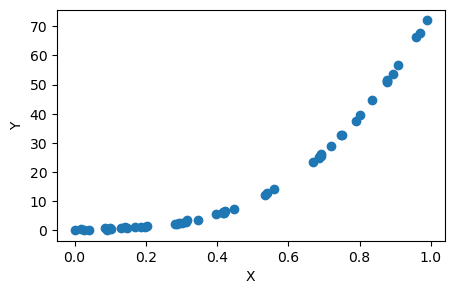

In [69]:
fig = plt.figure(figsize=(5,3))
plt.scatter(X, y, label="samples")
# plt.plot(X, output, label="prediction",color='orange')
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

0.8605173598742984


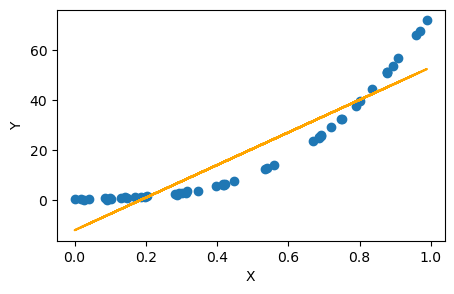

In [48]:

from sklearn.linear_model import LinearRegression



model = LinearRegression()
model.fit(X, y)

output = model.predict(X)

print(model.score(X,y))

fig = plt.figure(figsize=(5,3))
plt.scatter(X, y, label="samples")
plt.plot(X, output, label="prediction",color='orange')
plt.xlabel("X")
plt.ylabel("Y")
plt.show()



In [49]:
print(X.shape)

(50, 1)


In [52]:
# suppress scientific display numpy
np.set_printoptions(suppress=True)

In [54]:
0.417022 ** 2

0.173907348484

In [53]:
np.hstack([X, X**2])

array([[0.417022  , 0.17390735],
       [0.72032449, 0.51886738],
       [0.00011437, 0.00000001],
       [0.30233257, 0.09140498],
       [0.14675589, 0.02153729],
       [0.09233859, 0.00852642],
       [0.18626021, 0.03469287],
       [0.34556073, 0.11941222],
       [0.39676747, 0.15742443],
       [0.53881673, 0.29032347],
       [0.41919451, 0.17572404],
       [0.6852195 , 0.46952576],
       [0.20445225, 0.04180072],
       [0.87811744, 0.77109023],
       [0.02738759, 0.00075008],
       [0.67046751, 0.44952668],
       [0.4173048 , 0.1741433 ],
       [0.55868983, 0.31213432],
       [0.14038694, 0.01970849],
       [0.19810149, 0.0392442 ],
       [0.80074457, 0.64119186],
       [0.96826158, 0.93753048],
       [0.31342418, 0.09823472],
       [0.69232262, 0.4793106 ],
       [0.87638915, 0.76805795],
       [0.89460666, 0.80032108],
       [0.08504421, 0.00723252],
       [0.03905478, 0.00152528],
       [0.16983042, 0.02884237],
       [0.8781425 , 0.77113426],
       [0.

In [50]:
np.hstack([X, X**2]).shape

(50, 2)

In [56]:
X.shape

(50, 1)

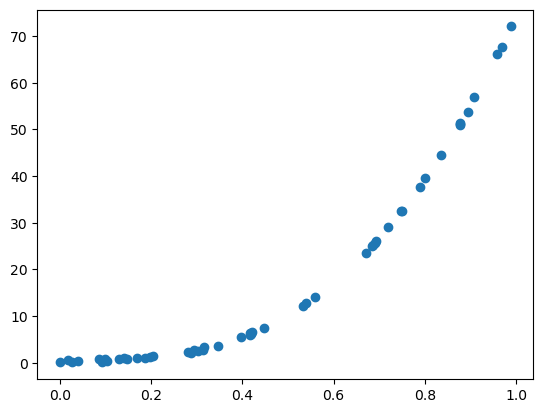

In [55]:
plt.scatter(X, y, label="samples")

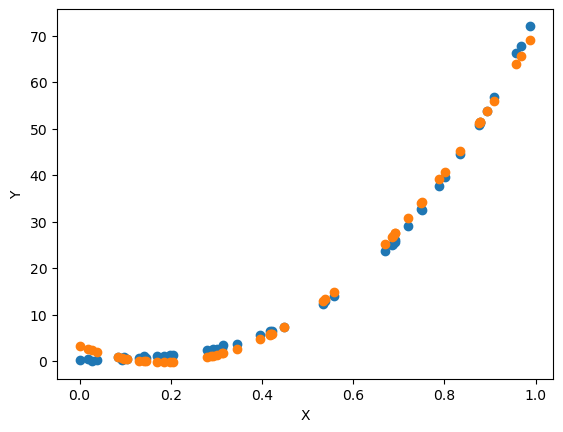

0.9959940506287053


In [4]:
from sklearn.preprocessing import StandardScaler

X_deg2 = np.hstack([X, X**2])

print("Shape of X: ", X.shape)
print("Shape of X_deg2: ", X_deg2.shape)


model_deg2 = LinearRegression()
model_deg2.fit(X_deg2, y)

y_hat = model_deg2.predict(X_deg2)

fig = plt.figure()
plt.scatter(X, y, label="samples")
plt.scatter(X, y_hat, label="prediction")

plt.xlabel("X")
plt.ylabel("Y")
plt.show()

print(model_deg2.score(X_deg2, y))


In [5]:
model_deg2.coef_,model_deg2.intercept_

(array([[-38.53737849, 106.22249468]]), array([3.30874832]))

[[4.17022005e-01 1.73907352e-01 7.25231927e-02]
 [7.20324493e-01 5.18867376e-01 3.73752880e-01]
 [1.14374817e-04 1.30815988e-08 1.49620548e-12]
 [3.02332573e-01 9.14049845e-02 2.76347041e-02]
 [1.46755891e-01 2.15372915e-02 3.16072440e-03]
 [9.23385948e-02 8.52641608e-03 7.87317280e-04]
 [1.86260211e-01 3.46928663e-02 6.46190062e-03]
 [3.45560727e-01 1.19412216e-01 4.12641722e-02]
 [3.96767474e-01 1.57424429e-01 6.24608929e-02]
 [5.38816734e-01 2.90323473e-01 1.56431145e-01]
 [4.19194514e-01 1.75724041e-01 7.36625540e-02]
 [6.85219500e-01 4.69525764e-01 3.21728209e-01]
 [2.04452250e-01 4.18007224e-02 8.54625174e-03]
 [8.78117436e-01 7.71090232e-01 6.77107778e-01]
 [2.73875932e-02 7.50080261e-04 2.05428931e-05]
 [6.70467510e-01 4.49526682e-01 3.01393035e-01]
 [4.17304802e-01 1.74143298e-01 7.26708346e-02]
 [5.58689828e-01 3.12134324e-01 1.74386272e-01]
 [1.40386939e-01 1.97084925e-02 2.76681493e-03]
 [1.98101489e-01 3.92442000e-02 7.77433445e-03]
 [8.00744569e-01 6.41191864e-01 5.134309

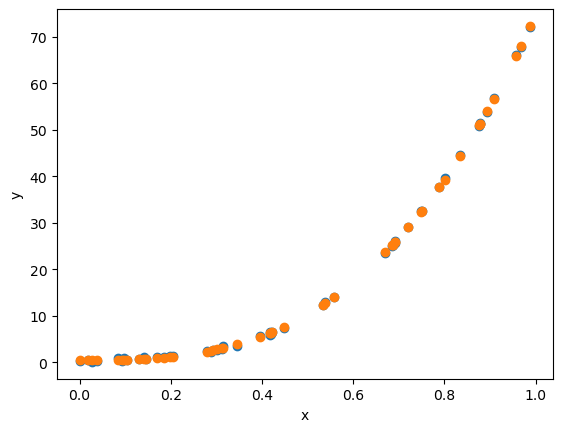

0.9998928512401912


In [6]:
X_deg3 = np.hstack([X, X**2, X**3])
print(X_deg3)
model_deg3 = LinearRegression()
model_deg3.fit(X_deg3, y)

y_hat = model_deg3.predict(X_deg3)

fig = plt.figure()
plt.scatter(X, y, label="samples")
plt.scatter(X, y_hat, label="prediction")

plt.xlabel("x")
plt.ylabel("y")
plt.show()
print(model_deg3.score(X_deg3, y))

# Polynomial Features

In [59]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=4)
X_poly = poly.fit_transform(X) # X**0, X**1, X**2, X**3, X**4
print(X_poly.shape) # shape of the generated features 4 features



(50, 5)


In [60]:
X_poly

array([[1.        , 0.417022  , 0.17390735, 0.07252319, 0.03024377],
       [1.        , 0.72032449, 0.51886738, 0.37375288, 0.26922335],
       [1.        , 0.00011437, 0.00000001, 0.        , 0.        ],
       [1.        , 0.30233257, 0.09140498, 0.0276347 , 0.00835487],
       [1.        , 0.14675589, 0.02153729, 0.00316072, 0.00046385],
       [1.        , 0.09233859, 0.00852642, 0.00078732, 0.0000727 ],
       [1.        , 0.18626021, 0.03469287, 0.0064619 , 0.00120359],
       [1.        , 0.34556073, 0.11941222, 0.04126417, 0.01425928],
       [1.        , 0.39676747, 0.15742443, 0.06246089, 0.02478245],
       [1.        , 0.53881673, 0.29032347, 0.15643115, 0.08428772],
       [1.        , 0.41919451, 0.17572404, 0.07366255, 0.03087894],
       [1.        , 0.6852195 , 0.46952576, 0.32172821, 0.22045444],
       [1.        , 0.20445225, 0.04180072, 0.00854625, 0.0017473 ],
       [1.        , 0.87811744, 0.77109023, 0.67710778, 0.59458015],
       [1.        , 0.02738759, 0.

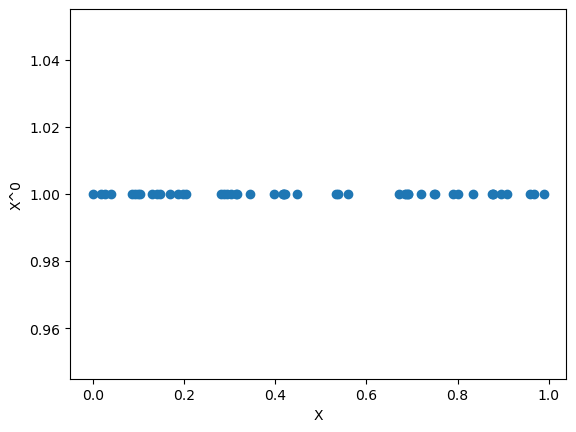

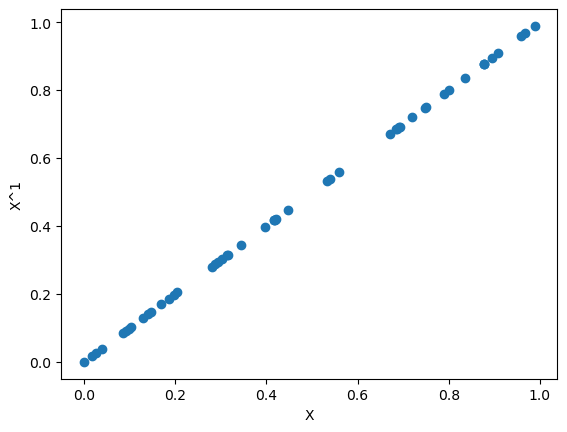

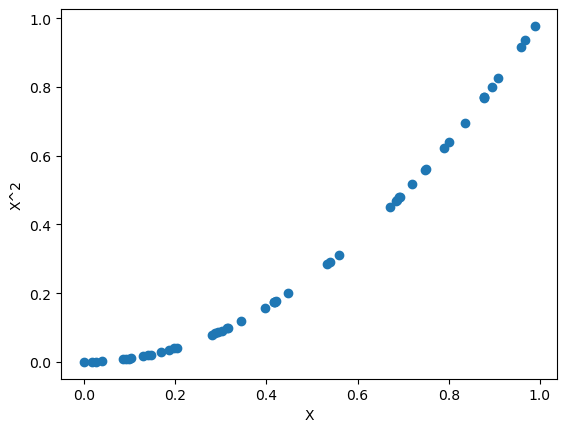

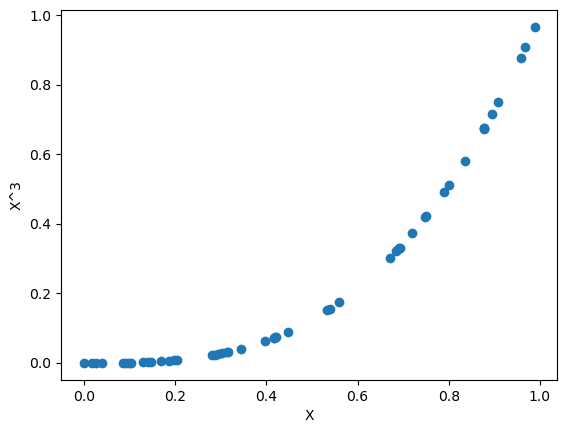

In [9]:
n_features = X_poly.shape[1]
for degree in range(n_features):
    fig = plt.figure()
    plt.scatter(X, X_poly[:,degree])
    plt.xlabel("X")
    plt.ylabel(f"X^{degree}")
    plt.show()

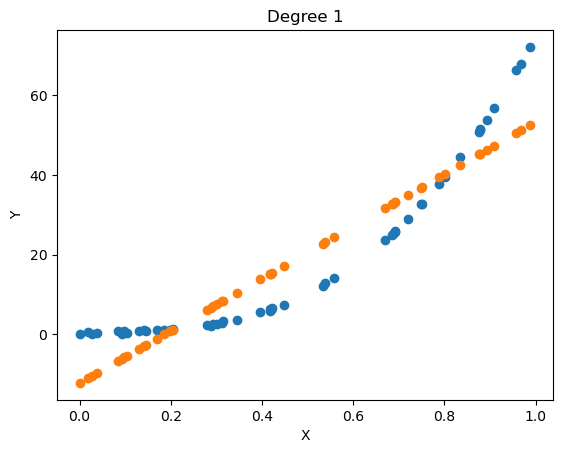

0.8605173598742984


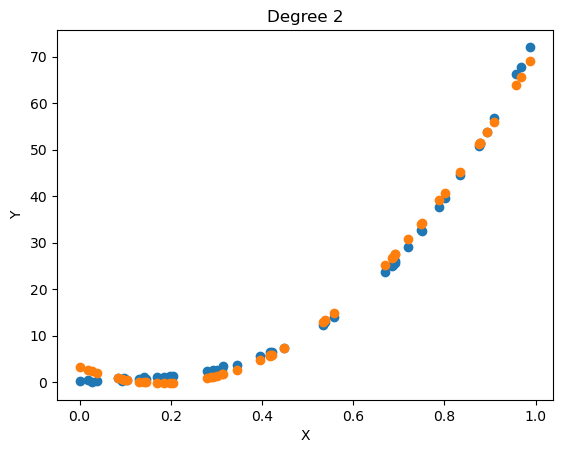

0.9959940506287053


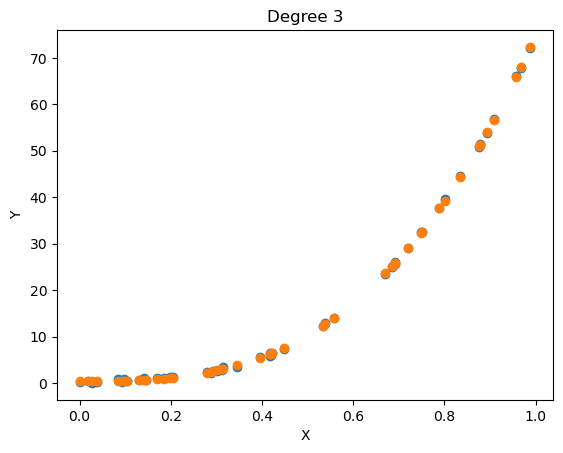

0.9998928512401912


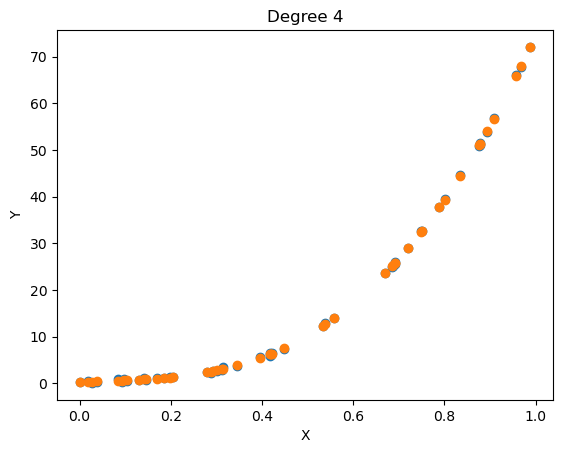

0.9999139850261068


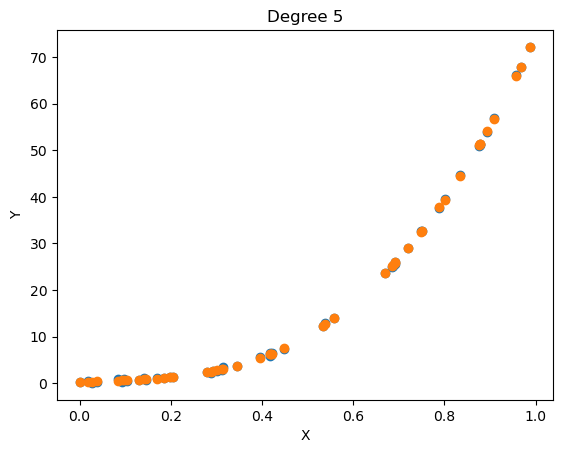

0.999914837435808


In [10]:
from sklearn.preprocessing import PolynomialFeatures

scores = []
for i in range(1, 6):
    poly = PolynomialFeatures(i)
    X_poly = poly.fit_transform(X)
    scaler = StandardScaler()
    scaler.fit(X_poly)
    X_poly_scaled = scaler.transform(X_poly)
    
    model = LinearRegression()
    model.fit(X_poly_scaled, y)
    y_hat = model.predict(X_poly_scaled)
    
    fig = plt.figure()
    plt.scatter(X, y, label="samples")
    plt.scatter(X, y_hat, label="prediction")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title(f"Degree {i}")
    plt.show()
    
    score = model.score(X_poly_scaled, y)
    print(score)
    scores.append(score)

In [11]:
scores

[0.8605173598742984,
 0.9959940506287053,
 0.9998928512401912,
 0.9999139850261068,
 0.999914837435808]

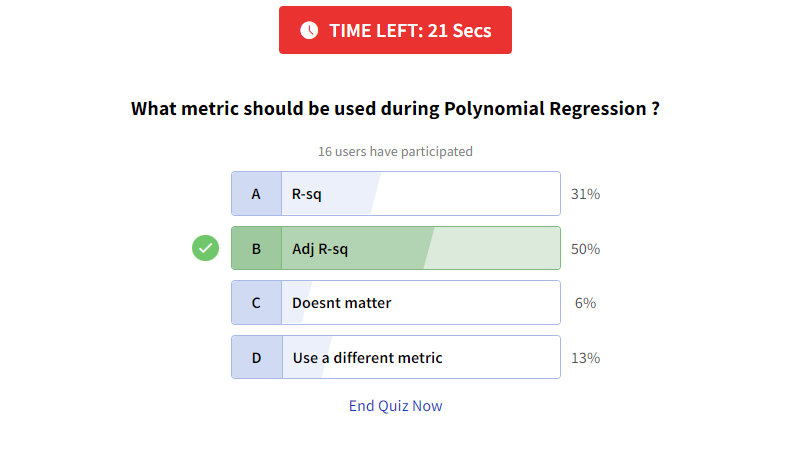

In [12]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

degree = 50 # number of data-points
scores = []
for i in range(0, degree):
    poly = PolynomialFeatures(i)
    X_poly = poly.fit_transform(X)
    scaler = StandardScaler()
    scaler.fit(X_poly)
    X_poly_scaled = scaler.transform(X_poly)
    model = LinearRegression()
    model.fit(X_poly_scaled, y)
    output = model.predict(X_poly_scaled)
    scores.append(model.score(X_poly_scaled, y))

best_deg = np.argmax(scores)
print(best_deg, scores[best_deg])

31 0.999944694487144


In [13]:
scores


[0.0,
 0.8605173598742984,
 0.9959940506287053,
 0.9998928512401912,
 0.9999139850261068,
 0.999914837435808,
 0.999915152296799,
 0.999915537933233,
 0.9999165672719849,
 0.9999176438298204,
 0.9999209468761652,
 0.9999214338338779,
 0.9999214446044237,
 0.999923964406723,
 0.9999260153694038,
 0.9999286756007999,
 0.9999286787909258,
 0.9999334329745073,
 0.9999334334252111,
 0.9999336811721252,
 0.999940381958336,
 0.9999403313946562,
 0.9999403502379847,
 0.9999402295783886,
 0.9999436948456576,
 0.9999436716506641,
 0.9999434793232984,
 0.9999436748440902,
 0.9999434790667165,
 0.9999433622327522,
 0.999943182987915,
 0.999944694487144,
 0.9987154229241936,
 0.9983937595142333,
 0.9979619001829169,
 0.9975130473928236,
 0.9991172339669504,
 0.9999442446859595,
 0.9993067646528688,
 0.998679881145569,
 0.997766886178532,
 0.9975872999688216,
 0.9979284532060592,
 0.9987295433079113,
 0.9986125393169192,
 0.9984695891232878,
 0.9984395715038824,
 0.9982655089722694,
 0.9981167130014

# This is with degree 5 

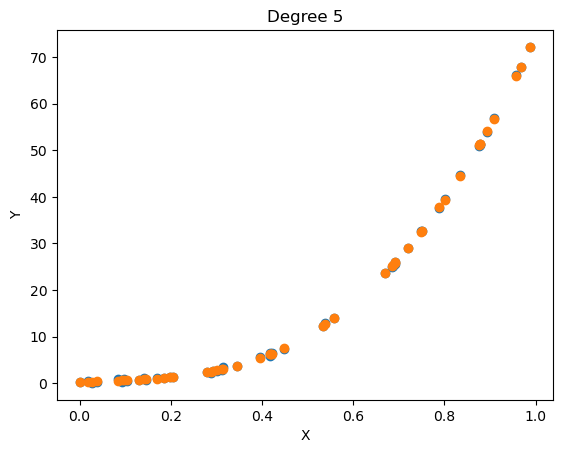

0.999914837435808


In [14]:
poly = PolynomialFeatures(5)
X_poly = poly.fit_transform(X)
scaler = StandardScaler()
scaler.fit(X_poly)
X_poly_scaled = scaler.transform(X_poly)

model = LinearRegression()
model.fit(X_poly_scaled, y)
output = model.predict(X_poly_scaled)

fig = plt.figure()
plt.scatter(X, y, label="ground truth")
plt.scatter(X, output, label="prediction")
plt.xlabel("X")
plt.ylabel("Y")
plt.title(f"Degree {5}")
plt.show()
print(model.score(X_poly_scaled, y))

# This is with degree 31

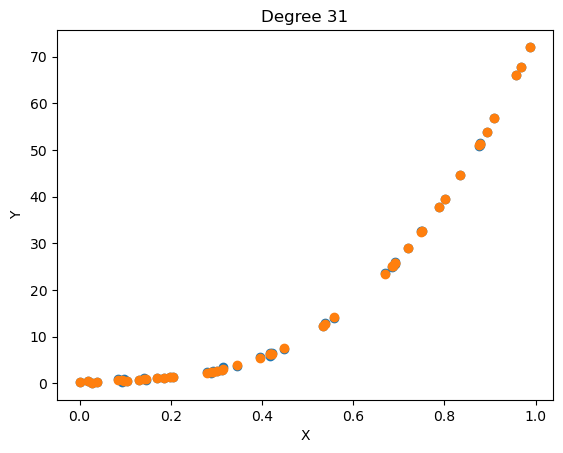

0.999944694487144


In [15]:
poly = PolynomialFeatures(31)
X_poly = poly.fit_transform(X)
scaler = StandardScaler()
scaler.fit(X_poly)
X_poly_scaled = scaler.transform(X_poly)

model = LinearRegression()
model.fit(X_poly_scaled, y)
output = model.predict(X_poly_scaled)

fig = plt.figure()
plt.scatter(X, y, label="ground truth")
plt.scatter(X, output, label="prediction")
plt.xlabel("X")
plt.ylabel("Y")
plt.title(f"Degree {31}")
plt.show()
print(model.score(X_poly_scaled, y))

In [62]:
np.random.seed(1)
X = np.random.rand(50,1)
y = 0.7*(X**5) - \
    2.1*(X**4) + \
    2.7*(X**3) + \
    3.5*(X**2) + \
    0.3* X + \
    0.4*4*np.random.rand(50,1)

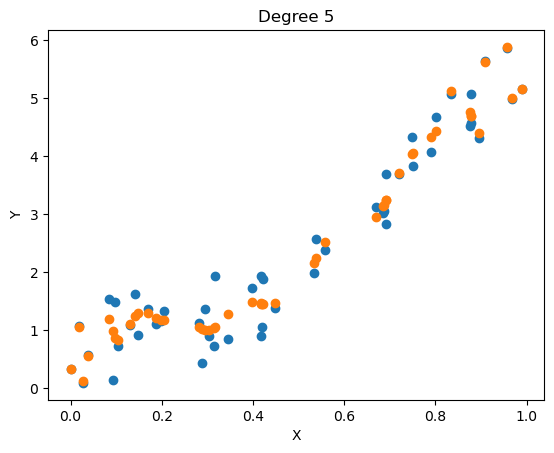

0.9626764779290151


In [63]:
poly = PolynomialFeatures(31)
X_poly = poly.fit_transform(X)
scaler = StandardScaler()
scaler.fit(X_poly)
X_poly_scaled = scaler.transform(X_poly)

model = LinearRegression()
model.fit(X_poly_scaled, y)
output = model.predict(X_poly_scaled)

fig = plt.figure()
plt.scatter(X, y, label="ground truth")
plt.scatter(X, output, label="prediction")
plt.xlabel("X")
plt.ylabel("Y")
plt.title(f"Degree {5}")
plt.show()
print(model.score(X_poly_scaled, y))

In [18]:
model.coef_

array([[-9.61077692e+11,  2.90610427e+02, -3.52174982e+04,
         1.60663154e+06, -3.97620900e+07,  6.20035277e+08,
        -6.59504191e+09,  5.01239042e+10, -2.79724556e+11,
         1.16162408e+12, -3.59030614e+12,  8.11972933e+12,
        -1.27892403e+13,  1.21333593e+13, -2.63964767e+12,
        -8.29694031e+12,  6.99955190e+12,  4.90826890e+12,
        -7.36055528e+12, -4.56095163e+12,  7.71702070e+12,
         5.62015140e+12, -9.28521121e+12, -4.91670989e+12,
         8.93567524e+12,  5.17499358e+12, -1.05310751e+13,
        -1.96783851e+12,  1.21460800e+13, -9.67323856e+12,
         3.40345413e+12, -4.72580102e+11]])

In [19]:
X_poly_scaled.shape

(50, 32)

In [20]:
np.argmax(np.abs(model.coef_))

12

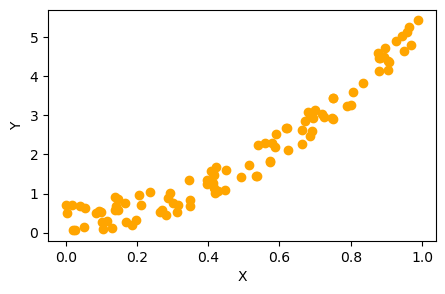

In [64]:
# lets first generate a dataset of 100 points this time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)
X = np.random.rand(100,1)
y = 0.7*(X**5) - \
    2.1*(X**4) + \
    2.7*(X**3) + \
    3.5*(X**2) + \
    0.3* X + \
    0.4*2*np.random.rand(100,1)

fig = plt.figure(figsize=(5,3))
plt.scatter(X, y,c="orange")
plt.xlabel("X")
plt.ylabel("Y")
plt.show()


from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [65]:
def adj_r(r_sq,X,Y):
  adj_r1 = (1 - ((1-r_sq)*(len(Y)-1))/(len(Y)-X.shape[1]-1) )
  return adj_r1

In [66]:
def r2_score(y,y_):
    num = np.sum((y-y_)**2)
    denom = np.sum((y- y.mean())**2)
    score = (1- num/denom)
    return score

In [24]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

degrees = 100 # number of data-points
train_scores = []
test_scores = []

train_loss = []
test_loss = []

scaler = StandardScaler()

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
for degree in range(1, degrees):

    polyreg_scaled = make_pipeline(PolynomialFeatures(degree), scaler, LinearRegression())
    polyreg_scaled.fit(X_train, y_train)

    train_score = polyreg_scaled.score(X_train, y_train)
    test_score = polyreg_scaled.score(X_test, y_test)

    train_scores.append(adj_r(train_score,X_train,y_train))
    test_scores.append(adj_r(test_score,X_test,y_test))

    output1 = polyreg_scaled.predict(X_train)
    output2 = polyreg_scaled.predict(X_test)

    train_loss.append(mean_squared_error(y_train,output1))
    test_loss.append(mean_squared_error(y_test,output2))


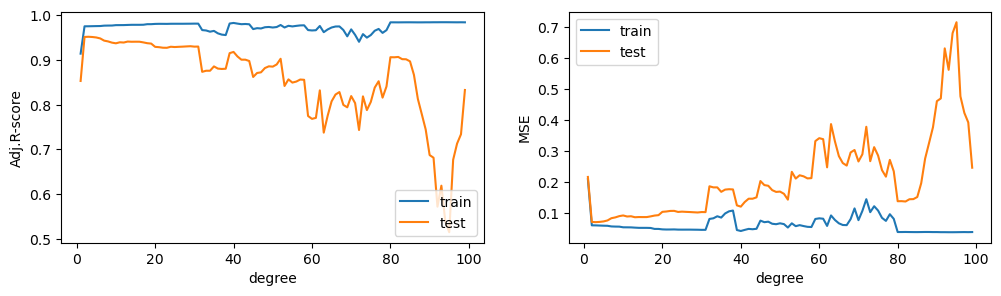

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].plot(list(range(1, 100)), train_scores, label="train")
axes[0].plot(list(range(1, 100)), test_scores, label="test")
axes[0].legend(loc='lower right')
axes[0].set_xlabel("degree")
axes[0].set_ylabel("Adj.R-score")

axes[1].plot(list(range(1, 100)), train_loss, label="train")
axes[1].plot(list(range(1, 100)), test_loss, label="test")
axes[1].legend(loc='upper left')
axes[1].set_xlabel("degree")
axes[1].set_ylabel("MSE")

plt.show()

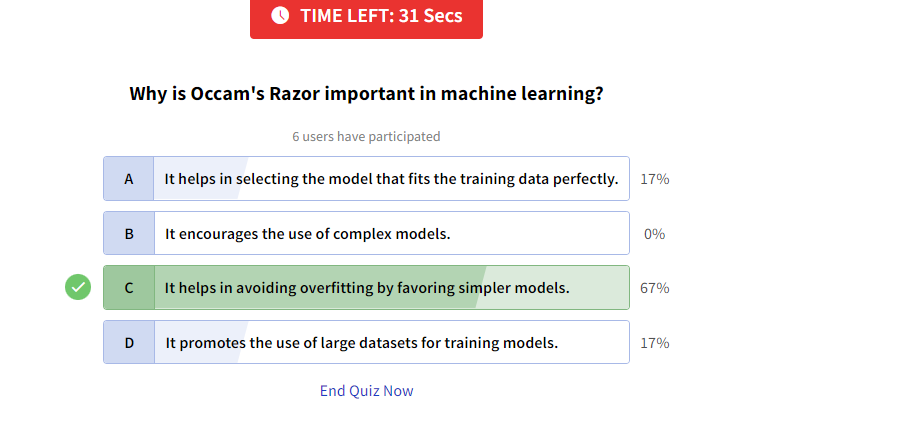

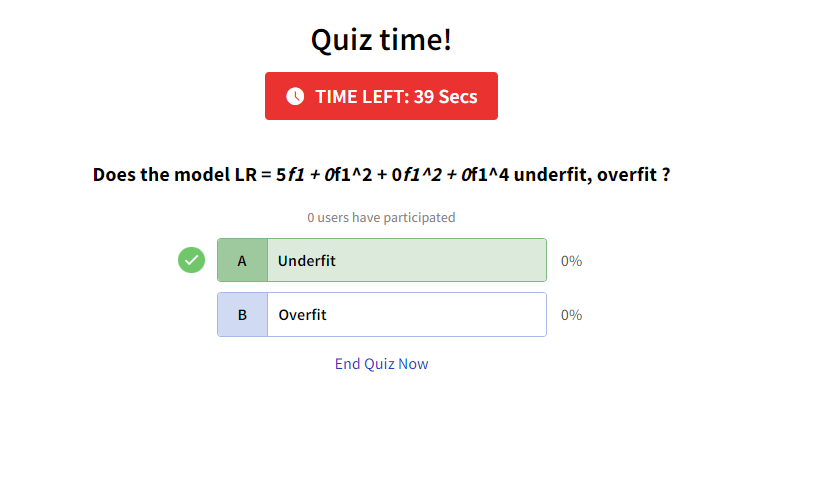

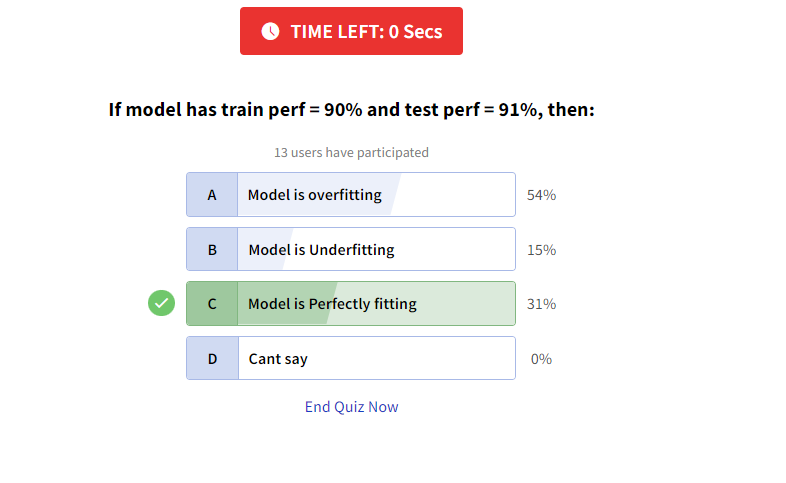

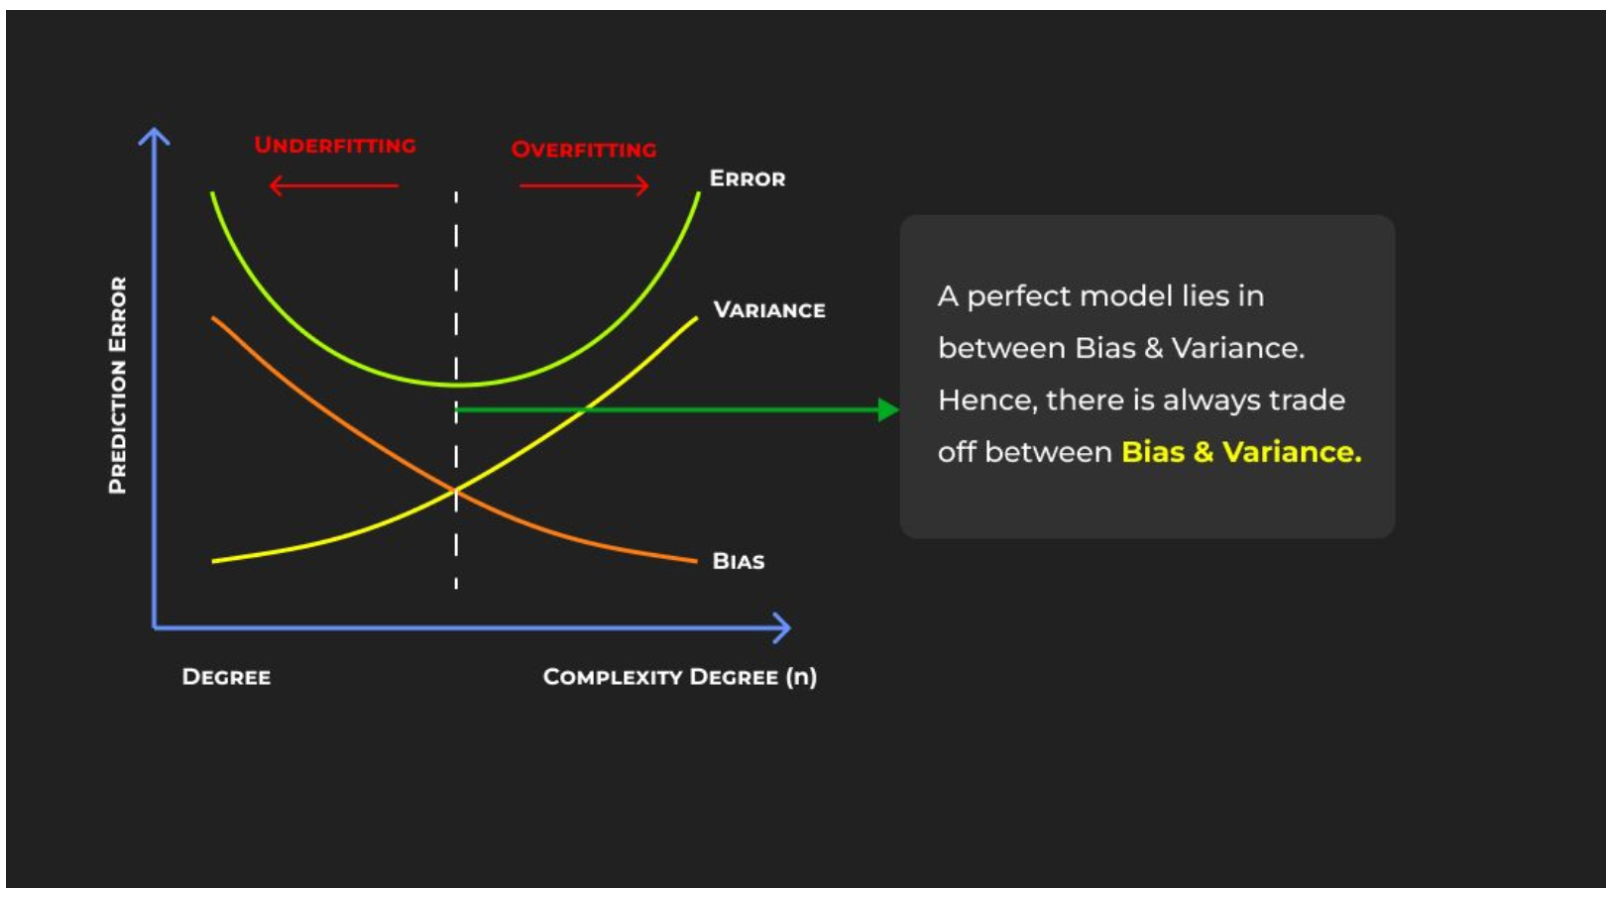

In [26]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
class LinearRegression():
    def __init__(self,learning_rate =0.1,iteration=5):
        self.learning_rate=learning_rate
        self.iteration = iteration

In [28]:
def predict(self,X):
    return np.dot(X,self.W) + self.b

LinearRegression.predict = predict

In [29]:
def r2_score(self,X,y):
    y_ = self.predict(X)
    ss_res = np.sum((y - y_)**2)
    ss_total = np.sum((y - y.mean())**2)
    score = 1 - (ss_res/ss_total)
    return score
LinearRegression.r2_score = r2_score

In [30]:
def update_weights(self):
    Y_pred = self.predict(self.X)
    
    # calculate the gradients
    dW = - ((2*self.X.T).dot(self.Y - Y_pred))/self.m
    db = - (2*np.sum(self.Y - Y_pred))/self.m
    
    self.W = self.W - (self.learning_rate * dW)
    self.b = self.b - (self.learning_rate * db)
    return self
LinearRegression.update_weights = update_weights

In [31]:
def fit(self,X, Y):
    self.m, self.d = X.shape
    
    # weight initialisation
    self.W = np.zeros(self.d)
    self.b = 0
    self.X = X
    self.Y = Y
    self.error_list = []
    
    # gradient descent learning
    for i in range(self.iteration):
        self.update_weights()
#         Y_pred = X.dot(self.W) + self.b
#         error = np.square(np.subtract(Y,Y_pred)).mean()
#         self.error_list.append(error)
    return self

LinearRegression.fit = fit

In [32]:
!gdown 1bwRmKkPwmLKiqOgQ_LnKH0Vsc3mJKmVR

Downloading...
From: https://drive.google.com/uc?id=1bwRmKkPwmLKiqOgQ_LnKH0Vsc3mJKmVR
To: c:\Users\Shivam\Documents\scaler\intro_to_ml\niks\05_Polynomial_Regression\cars24-car-price-cleaned.csv

  0%|          | 0.00/1.69M [00:00<?, ?B/s]
 31%|███       | 524k/1.69M [00:00<00:00, 1.50MB/s]
100%|██████████| 1.69M/1.69M [00:00<00:00, 4.37MB/s]
100%|██████████| 1.69M/1.69M [00:00<00:00, 3.71MB/s]


In [33]:
df = pd.read_csv('cars24-car-price-cleaned.csv')
df.head()

,selling_price,year,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
0,1.20,2012.0,120000,19.70,796.0,46.30,11.0,MARUTI,ALTO STD,1,0,0,0,0,1,1,1,0
1,5.50,2016.0,20000,18.90,1197.0,82.00,7.0,HYUNDAI,GRAND I10 ASTA,1,0,0,0,0,1,1,1,0
2,2.15,2010.0,60000,17.00,1197.0,80.00,13.0,HYUNDAI,I20 ASTA,1,0,0,0,0,1,1,1,0
3,2.26,2012.0,37000,20.92,998.0,67.10,11.0,MARUTI,ALTO K10 2010-2014 VXI,1,0,0,0,0,1,1,1,0
4,5.70,2015.0,30000,22.77,1498.0,98.59,8.0,FORD,ECOSPORT 2015-2021 1.5 TDCI TITANIUM BSIV,0,0,1,0,0,0,1,1,0


In [34]:
df["make"]=df.groupby("make")["selling_price"].transform("mean")
df["model"]=df.groupby("model")["selling_price"].transform("mean")

In [35]:
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler()

In [36]:
df1=pd.DataFrame(min_max_scaler.fit_transform(df[['year', 'km_driven', 'mileage', 'engine', 'max_power',
       'age', 'make', 'model', 'Individual', 'Trustmark Dealer', 'Diesel',
       'Electric', 'LPG', 'Petrol', 'Manual', '5', '>5']]),columns= ['year', 'km_driven', 'mileage', 'engine', 'max_power',
       'age', 'make', 'model', 'Individual', 'Trustmark Dealer', 'Diesel',
       'Electric', 'LPG', 'Petrol', 'Manual', '5', '>5'])
df1

,year,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
0,0.689655,0.031553,0.135345,0.117891,0.066506,0.310345,0.194048,0.041550,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
1,0.827586,0.005237,0.128448,0.177281,0.123994,0.172414,0.232517,0.218382,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
2,0.620690,0.015764,0.112069,0.177281,0.120773,0.379310,0.232517,0.149143,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
3,0.689655,0.009711,0.145862,0.147808,0.100000,0.310345,0.194048,0.093193,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
4,0.793103,0.007869,0.161810,0.221860,0.150709,0.206897,0.252367,0.313574,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19815,0.862069,0.018258,0.168879,0.202014,0.099919,0.137931,0.484670,0.328028,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
19816,0.931034,0.004711,0.116379,0.203347,0.138647,0.068966,0.194048,0.330632,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0
19817,0.793103,0.017606,0.147759,0.221860,0.158647,0.206897,0.318156,0.200656,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
19818,0.827586,1.000000,0.103448,0.322719,0.217391,0.172414,0.324782,0.377671,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0


In [37]:
y = df["selling_price"]
y

0         1.20
1         5.50
2         2.15
3         2.26
4         5.70
         ...  
19815     6.50
19816     9.25
19817     4.25
19818    12.25
19819    12.00
Name: selling_price, Length: 19820, dtype: float64

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df1,y,test_size=0.2,random_state= 10)

In [39]:
model = LinearRegression(iteration=1200)

In [40]:
model.fit(X_train,y_train)

In [41]:
model.predict(X_test)

array([ 1.80062144,  4.87259708, 20.19567196, ...,  8.81949507,
        3.49227225,  5.54356009])

In [42]:
model.W

year                 2.855929
km_driven           -0.453551
mileage             -1.117041
engine               1.908561
max_power            2.742976
age                 -3.515266
make                 2.782204
model               16.067876
Individual          -0.137464
Trustmark Dealer    -0.170975
Diesel               0.013552
Electric             0.125232
LPG                  0.184528
Petrol              -0.167846
Manual              -0.193688
5                   -0.278838
>5                  -0.269345
dtype: float64

Text(0, 0.5, 'Error')

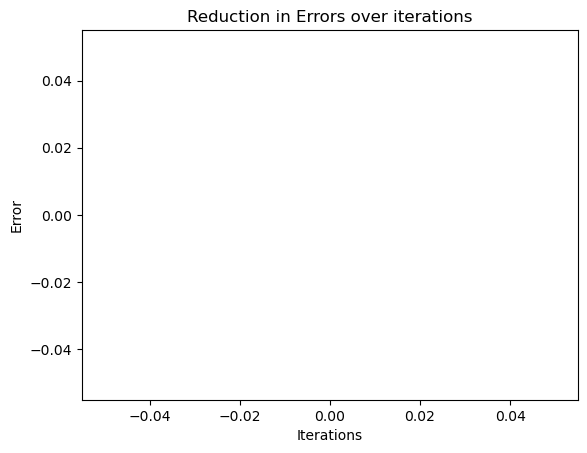

In [43]:
%matplotlib inline
fig = plt.figure()
plt.plot(model.error_list)
plt.title("Reduction in Errors over iterations")
plt.xlabel("Iterations")
plt.ylabel("Error")

In [44]:
model.X

,year,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
19738,0.827586,0.023659,0.077500,0.369372,0.153945,0.172414,0.484670,0.393816,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
17034,0.862069,0.016528,0.210345,0.184834,0.111111,0.137931,0.194048,0.243142,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
17080,0.793103,0.020597,0.144569,0.184834,0.134879,0.206897,0.194048,0.290510,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
7420,0.827586,0.005237,0.143276,0.177429,0.099839,0.172414,0.120521,0.121897,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0
15375,0.862069,0.019448,0.110345,0.221712,0.179227,0.137931,0.258412,0.292240,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9372,0.620690,0.047343,0.112069,0.221712,0.181965,0.379310,0.258412,0.211097,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
7291,0.896552,0.009882,0.153362,0.147808,0.099919,0.103448,0.194048,0.146016,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
17728,0.896552,0.009974,0.159828,0.206754,0.134879,0.103448,0.232517,0.416717,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
7293,0.758621,0.018428,0.130172,0.177281,0.130113,0.241379,0.194048,0.194698,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0


In [45]:
model.Y

19738    9.45
17034    7.00
17080    7.85
7420     3.50
15375    8.50
         ... 
9372     4.00
7291     4.70
17728    8.75
7293     4.45
17673    7.75
Name: selling_price, Length: 15856, dtype: float64